# Explainable Fake Review Detection System using Machine Learning and SHAP Analysis

### 1. Research Aim:
Develop and evaluate an explainable machine learning system capable of distinguishing between:
- **Genuine Reviews** (truthful)
- **Human-Written Fake Reviews** (deceptive)
- **AI-Generated Reviews**

while assessing the usefulness of SHAP explanations.

### 2. Research Questions:
- **RQ1:** Can XGBoost accurately classify reviews into Genuine, Human Fake and AI-Generated categories?
- **RQ2:** Which textual features contribute most to the detection of each review type?
- **RQ3:** Can SHAP effectively explain the predictions of the model?
- **RQ4:** Do SHAP explanations increase participant confidence and perceived understanding of review authenticity? (outlined for human evaluation)

### 3. Datasets:
1. **Deceptive Opinion Spam Corpus:** (hotel reviews) + AI-generated reviews → main 3-class balanced dataset (800 per class).
2. **Amazon genuine product reviews sample:** → used for domain comparison and generalisation check.

## Overview Report: Data Sources, Variable Selection and Methodology

### 1. Purpose of the Study:
- Builds an explainable fake-review detection system.
- Classifies a review into one of three classes: **Genuine**, **Human Fake** (deceptive, written by people) or **AI Generated**.
- Uses machine learning on the review text and SHAP to show which words drive each prediction.
- Answers four research questions (RQ1 to RQ4). RQ4 (human evaluation) is not run in this notebook.

### 2. Data Sources:
**Dataset 1: Main 3-class dataset (`deceptive-opinion-augmented.csv`)**

- The Deceptive Opinion Spam Corpus (hotel reviews) was augmented with AI-generated reviews.
- Final file has **2,400 rows and 5 columns** (`label`, `hotel`, `polarity`, `source`, `text`) and is perfectly balanced (800 per class).
- The original dataset has 1,600 records: 800 `truthful` and 800 `deceptive`.
- The third class (AI Generated, 800 records) was generated using Claude.
- **Prompt used to generate the data:** Using the attached dataset as a reference, generate 800 new, unique AI-generated deceptive opinion/review responses that follow the same writing style, structure, length, and format as the existing records. Add a label column with the value "AI generated" for all 800 records. Ensure the generated responses are diverse, realistic, and non-duplicate, and maintain the same dataset structure. Do not modify the existing 1,600 records. Export the final dataset as a CSV file.

| Class | Reviews | Source |
|---|---|---|
| Genuine (`truthful`) | 800 | TripAdvisor (400) and Web (400) |
| Human Fake (`deceptive`) | 800 | MTurk (crowd-workers asked to write fake reviews) |
| AI Generated (`AI generated`) | 800 | AI generated |

- Polarity is also balanced: 1,200 positive and 1,200 negative reviews.

**Dataset 2: Amazon genuine sample (`amazon_genuine_sample.csv`):**

- Holds 2,000 genuine Amazon product reviews with 9 columns.
- After removing empty reviews, reviews of 20 characters or fewer, and 7 rows with an invalid star rating, **1,788 reviews** remain.
- Used only for (a) a domain comparison with hotel reviews and (b) a generalisation check. It is never used for training.

### 3. Variables:
**Main dataset:**

| Variable | Role in this study | Explanation |
|---|---|---|
| `text` (cleaned to `clean_text`) | **Only model input** | The review text. TF-IDF features (6,000 unigrams and bigrams) are built from the cleaned text. |
| `label` | **Target variable** | truthful / deceptive / AI generated, encoded as numbers for modelling. |
| `polarity` | EDA only | Positive or negative sentiment of the review. Used to check that classes are balanced in sentiment. |
| `source` | EDA only | Where the review came from. Not used for modelling (see below). |
| `hotel` | Not used | Which hotel the review is about. Not relevant to authenticity. |
| `char_length`, `word_count` | EDA only | Engineered in the notebook to compare review length across classes. |

- **Why only the text is used as a predictor:**
  - `source` identifies the class almost perfectly (all MTurk reviews are Human Fake and all "AI generated" source reviews are AI Generated).
  - Using it would let the model "cheat" through data leakage instead of learning from the language.
  - Keeping only the text forces the model to learn linguistic differences, which is also what SHAP needs to give meaningful explanations.
  - `hotel` and `polarity` carry no information about authenticity and would only add noise.

**Amazon sample:**

| Variable | Role | Explanation |
|---|---|---|
| `reviewText` (cleaned to `clean_text`) | Used | Review text, passed through the same preprocessing and TF-IDF as the main data. |
| `starRating` | Used for cleaning and EDA | Invalid entries (non-numeric text) were removed. 5-star reviews dominate (1,215 of 1,788). |
| `reviewerId`, `reviewId`, `verifiedPurchase`, `reviewDate`, `helpfulVote`, `reviewTitle`, `prodId` | Not used | Identifiers and metadata. They are not available in the hotel dataset and are not text features. |

### 4. Methodology Pipeline:
1. **Load and inspect** both datasets (shape, columns, class, polarity and source balance).
2. **EDA**: class balance, character and word length by class, polarity by class, source distribution, summary statistics, and hotel versus Amazon length comparison.
3. **Text preprocessing**: lowercase, remove punctuation and numbers, remove stop-words, drop tokens of 2 characters or fewer, lemmatise (WordNet).
4. **Label encoding and split**: 80% train (1,920) / 20% test (480), stratified, `random_state=42`. Each class has 640 training and 160 test reviews.
5. **TF-IDF**: up to 6,000 features, unigrams and bigrams, `min_df=3`, `max_df=0.90`. Fitted on the training data only, so no test information leaks in.
6. **Baseline model comparison** (default settings): Logistic Regression, Random Forest, Multinomial Naive Bayes and XGBoost.
7. **XGBoost tuning**: `RandomizedSearchCV` (12 candidate settings, 3-fold cross-validation, macro F1) on the training data only.
8. **Evaluation**: accuracy and macro precision, recall and F1 on the test set, plus the confusion matrix for the tuned XGBoost.
9. **Generalisation check**: the tuned XGBoost and Logistic Regression each classify the same 400 Amazon genuine reviews.
10. **Explainability**: SHAP TreeExplainer on 200 test reviews, with bar plots of the top 15 words per class.
11. **Human evaluation (RQ4)**: currently pending.

- **Why these models:**
  - Logistic Regression is a simple, interpretable linear baseline for sparse text features.
  - Naive Bayes is a classic fast text classifier.
  - Random Forest is a non-linear ensemble.
  - XGBoost is a boosted-tree ensemble that handles complex word interactions and is directly supported by SHAP's TreeExplainer.

### 5. Results Summary:

| Model | Accuracy | Macro F1 |
|---|---|---|
| Logistic Regression | **0.9333** | **0.9330** |
| Naive Bayes | 0.9250 | 0.9248 |
| XGBoost (baseline, default settings) | 0.8854 | 0.8848 |
| Tuned XGBoost | 0.8750 | 0.8747 |
| Random Forest | 0.8375 | 0.8339 |

- **Logistic Regression performed best** on the hotel test set (93.33% accuracy), followed by Naive Bayes (92.50%).
- **Tuning did not raise test accuracy for XGBoost:** it moved from 0.8854 (baseline) to 0.8750 (tuned), and macro F1 from 0.8848 to 0.8747. Best cross-validation macro F1 on the training data was 0.8548.
- **Best tuned settings:** `n_estimators=300`, `max_depth=3`, `learning_rate=0.1`, `min_child_weight=3`, `gamma=0.1`, `subsample=1.0`, `colsample_bytree=1.0`.
- **Tuned XGBoost (primary model)** classifies 420 of 480 test reviews correctly.
  - AI Generated: 155 of 160 correct (precision 0.951, recall 0.969, F1 0.960).
  - Human Fake: 132 of 160 correct (precision 0.857, recall 0.825, F1 0.841).
  - Genuine: 133 of 160 correct (precision 0.816, recall 0.831, F1 0.824).
  - 47 of the 60 errors are between Human Fake and Genuine.
- **Argument: Logistic Regression performed best on the hotel test set, but Tuned XGBoost gave better accuracy in generalisation.**
  - On the same 400 genuine Amazon reviews, Tuned XGBoost predicted **368 (92.0%)** as Genuine, against **330 (82.5%)** for Logistic Regression.
  - Tuned XGBoost made **0** AI Generated predictions on these reviews, against 13 for Logistic Regression.
  - Human Fake predictions were 32 for Tuned XGBoost and 57 for Logistic Regression.
  - Every Amazon review in the sample is genuine, so the percentage predicted Genuine is the accuracy on that sample. This is why Tuned XGBoost is kept as the primary model, together with its SHAP support.
- **Domain shift:** Amazon reviews are much shorter (about 253 characters and 47 words) than hotel reviews (about 821 characters and 151 words).
- **Length and the classes:** Human Fake and Genuine reviews have similar lengths (mean about 147 and 151 words). AI Generated reviews are slightly shorter (mean 131 words) and far less spread out (standard deviation 36 words against about 85 to 90), so length is not a strong clue between Human Fake and Genuine.

### 6. SHAP Findings (what the words show):
- **AI Generated class:** hotel-service and everyday-narrative words such as *chicago, hotel, room, bed, staff, desk, said, morning, evening, asked, front desk*.
- **Human Fake class:** room-feature and emphatic words such as *small, chicago, floor, morning, quiet, breakfast, food, elevator, definitely, luxury, experience*.
- **Genuine class:** place names and specific stay details such as *chicago, location, michigan, arrived, smelled, call, construction, hour, talbott hotel, house hilton*.
- Several words (for example *chicago*) rank high in more than one class. The bar plots show how strongly a word influences a class, not in which direction.

### 7. Important Notes for the Theory Writer (limitations and points to check):
1. **AI data is from one source:** all AI reviews were generated by one tool (Claude) from one prompt that copied the style of the existing reviews. The AI class may be easier to detect than text from other AI tools.
2. **Tuning was applied to XGBoost only.** Logistic Regression, Naive Bayes and Random Forest use default settings, so the comparison is not fully like-for-like.
3. **Single train/test split.** Test results come from one 80/20 split (cross-validation was used only inside the tuning step).
4. **Amazon check has no fake examples and uses one sample of 400 reviews** (`random_state=42`, same reviews for both models). It shows how often genuine reviews are called Genuine (92.0% for Tuned XGBoost, 82.5% for Logistic Regression), not full detection accuracy. The generalisation advantage of Tuned XGBoost should be reported with this in mind.
5. **Corpus-specific words:** words like *chicago*, *michigan* and *location* rank high in SHAP. The original hotel corpus is about Chicago hotels, so some patterns may not transfer to other domains.

## 1. Import Libraries & Setup

This cell imports the libraries for:
- data handling (pandas, numpy
-  plotting (matplotlib, seaborn)
- text preprocessing (NLTK)
- feature extraction
- evaluation (scikit-learn)
- modelling (XGBoost)
- explainability (SHAP).

It also downloads the NLTK resources (stop-words, tokenizer, WordNet) and defines the colour scheme used in every chart: green for Genuine, red for Human Fake and blue for AI Generated.

In [1]:
# import all the libraries needed
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('punkt')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB

import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV
import shap

# Consistent colour palette used throughout the notebook
CLASS_COLORS = {
    'AI generated':  '#3498db',
    'deceptive':     '#e74c3c',
    'truthful':      '#2ecc71'
}
CLASS_ORDER  = ['AI generated', 'deceptive', 'truthful']
CLASS_LABELS = [ 'AI Generated', 'Human Fake', 'Genuine']

# Extra colours for Amazon comparison
DOMAIN_COLORS = {
    'Hotel Genuine':  '#2ecc71',
    'Amazon Genuine': '#8e44ad'
}

print('Libraries loaded successfully.')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\gaura\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\gaura\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\gaura\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\gaura\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\gaura\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Libraries loaded successfully.


## 2. Load Main Hotel Dataset

- This code loads `deceptive-opinion-augmented.csv` and shows its shape and first rows.
- The dataset has **2,400 reviews and 5 columns** (`label`, `hotel`, `polarity`, `source`, `text`).
- The first rows are genuine TripAdvisor reviews of the Conrad and Hyatt hotels.

In [2]:
# read the hotel data
df = pd.read_csv('deceptive-opinion-augmented.csv')
print(f'Main dataset shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head(3)

Main dataset shape: (2400, 5)
Columns: ['label', 'hotel', 'polarity', 'source', 'text']


,label,hotel,polarity,source,text
0,truthful,conrad,positive,TripAdvisor,We stayed for a one night getaway with family ...
1,truthful,hyatt,positive,TripAdvisor,Triple A rate with upgrade to view room was le...
2,truthful,hyatt,positive,TripAdvisor,This comes a little late as I'm finally catchi...


- This code checks the balance of the three label classes, polarity and source.
- Each class has exactly **800 reviews**, and polarity is split evenly (1,200 positive and 1,200 negative).
- Sources are MTurk (800), AI generated (800), TripAdvisor (400) and Web (400).
- Perfect balance means accuracy is a fair metric and no resampling such as SMOTE is needed.

In [3]:
# check class, polarity and source counts
print('Class distribution (main 3-class dataset):')
print(df['label'].value_counts())
print('\nPolarity distribution:')
print(df['polarity'].value_counts())
print('\nSource distribution:')
print(df['source'].value_counts())

Class distribution (main 3-class dataset):
label
truthful        800
deceptive       800
AI generated    800
Name: count, dtype: int64

Polarity distribution:
polarity
positive    1200
negative    1200
Name: count, dtype: int64

Source distribution:
source
MTurk          800
AI             800
TripAdvisor    400
Web            400
Name: count, dtype: int64


## 3. Exploratory Data Analysis of Hotel Dataset

Consistent colour scheme:
- **Green** → Genuine (truthful)
- **Red** → Human Fake (deceptive)
- **Blue** → AI Generated

### 3.1 Class Balance

- This bar chart confirms that the three classes are perfectly balanced at 800 reviews each. The model therefore has no majority class to favour.

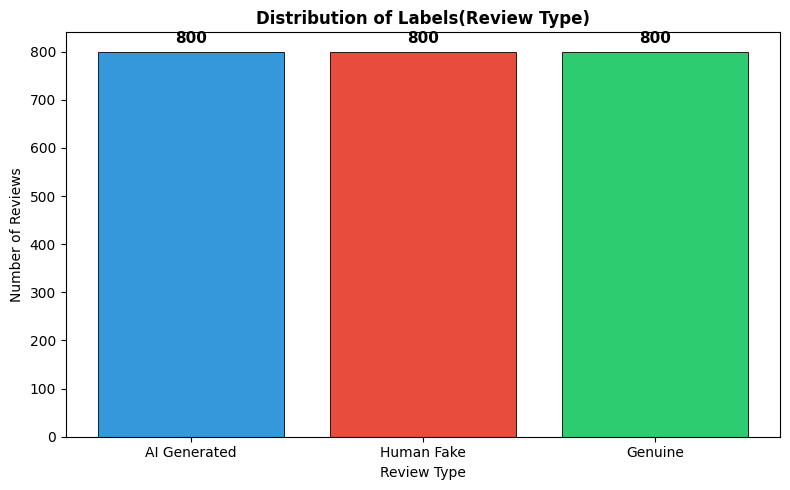

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
counts = df['label'].value_counts().reindex(CLASS_ORDER).fillna(0)
bars = ax.bar(CLASS_LABELS, counts.values,
              color=[CLASS_COLORS[c] for c in CLASS_ORDER],
              edgecolor='black', linewidth=0.6)

ax.set_title('Distribution of Labels(Review Type)', fontweight='bold')
ax.set_ylabel('Number of Reviews')
ax.set_xlabel('Review Type')

# show the count on top of each bar
for bar in bars:
    height = bar.get_height()
    val_str = f'{int(height)}' if not np.isnan(height) else '0'
    ax.annotate(val_str,
                xy=(bar.get_x() + bar.get_width()/2, height if not np.isnan(height) else 0),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

### 3.2 Character Length by Class

- This box plot compares the number of characters per review across classes.
- Human Fake and Genuine reviews overlap heavily and both contain many very long reviews.
- AI Generated reviews sit in a much narrower range with no extreme outliers.

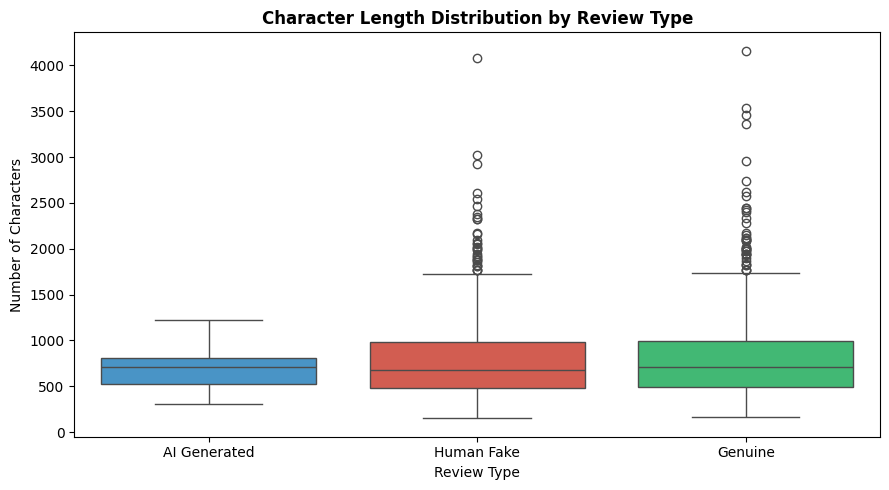

In [5]:
# length of each review in characters
df['char_length'] = df['text'].str.len()

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x='label', y='char_length',
            order=CLASS_ORDER, palette=CLASS_COLORS, ax=ax)

ax.set_xticklabels(CLASS_LABELS)
ax.set_title('Character Length Distribution by Review Type', fontweight='bold')
ax.set_xlabel('Review Type')
ax.set_ylabel('Number of Characters')

plt.tight_layout()
plt.show()

### 3.3 Word Count by Class

- This box plot compares word counts per class.
- Human Fake and Genuine have similar medians and spreads, with many long outliers (up to about 750 to 780 words).
- AI Generated reviews are more uniform (roughly 60 to 220 words, no outliers).
- Length does not separate Human Fake from Genuine, so the model has to rely on the wording.

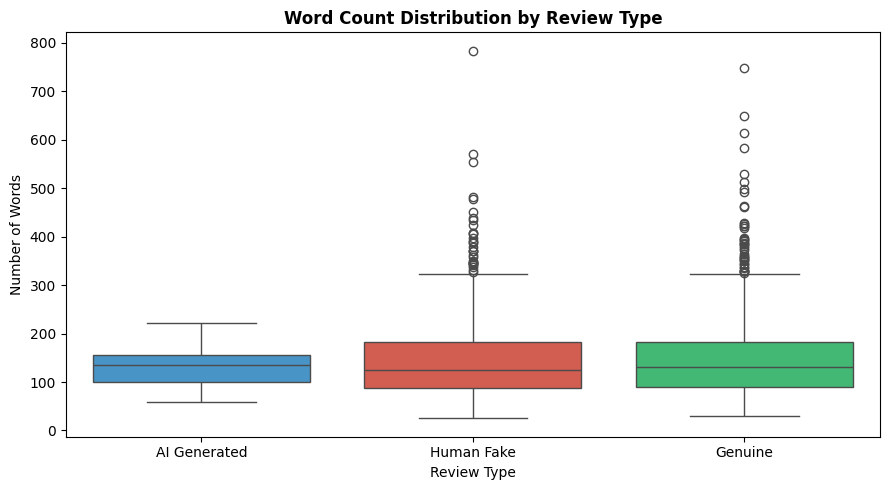

In [6]:
# number of words in each review
df['word_count'] = df['text'].str.split().str.len()

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x='label', y='word_count',
            order=CLASS_ORDER, palette=CLASS_COLORS, ax=ax)

ax.set_xticklabels(CLASS_LABELS)
ax.set_title('Word Count Distribution by Review Type', fontweight='bold')
ax.set_xlabel('Review Type')
ax.set_ylabel('Number of Words')

plt.tight_layout()
plt.show()

### 3.4 Average Word Count by Class

- This chart shows average words per review: about 151 for Genuine, 147 for Human Fake and 131 for AI Generated.
- Genuine and Human Fake are very close. AI Generated reviews are a little shorter on average.

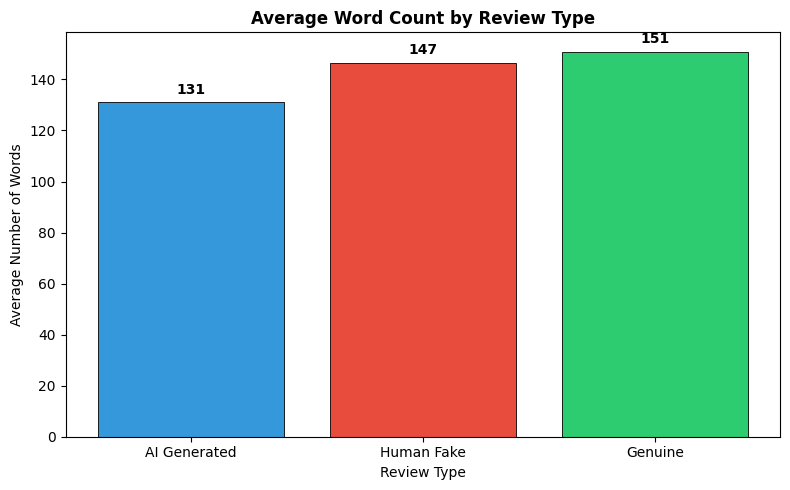

In [7]:
# average words per class
avg_words = df.groupby('label')['word_count'].mean().reindex(CLASS_ORDER)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(CLASS_LABELS, avg_words.values,
              color=[CLASS_COLORS[c] for c in CLASS_ORDER],
              edgecolor='black', linewidth=0.6)

ax.set_title('Average Word Count by Review Type', fontweight='bold')
ax.set_ylabel('Average Number of Words')
ax.set_xlabel('Review Type')

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.0f}',
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### 3.5 Polarity Distribution by Class

- This chart splits each class by positive and negative polarity. Sentiment is balanced overall (1,200 positive and 1,200 negative), so the classifier cannot use sentiment direction as a shortcut.

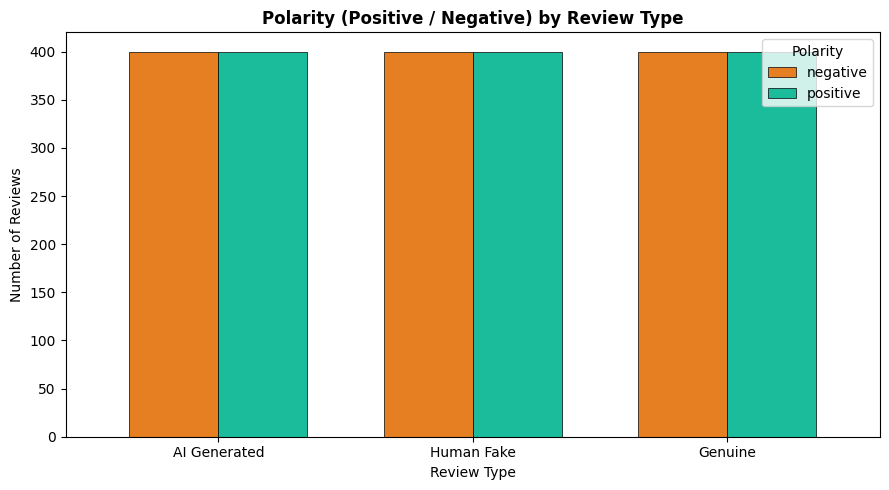

In [8]:
# positive/negative count for each class
polarity_ct = pd.crosstab(df['label'], df['polarity']).reindex(CLASS_ORDER)

fig, ax = plt.subplots(figsize=(9, 5))
polarity_ct.plot(kind='bar', ax=ax,
                 color=['#e67e22', '#1abc9c'],
                 edgecolor='black', linewidth=0.5, width=0.7)

ax.set_xticklabels(CLASS_LABELS, rotation=0)
ax.set_title('Polarity (Positive / Negative) by Review Type', fontweight='bold')
ax.set_xlabel('Review Type')
ax.set_ylabel('Number of Reviews')
ax.legend(title='Polarity')

plt.tight_layout()
plt.show()

### 3.6 Source Distribution

- This chart shows where the reviews come from. Source maps almost one-to-one onto the class (all MTurk reviews are deceptive, all "AI generated" source reviews are AI generated). This is the reason `source` is **excluded** from the model inputs: using it would cause data leakage.

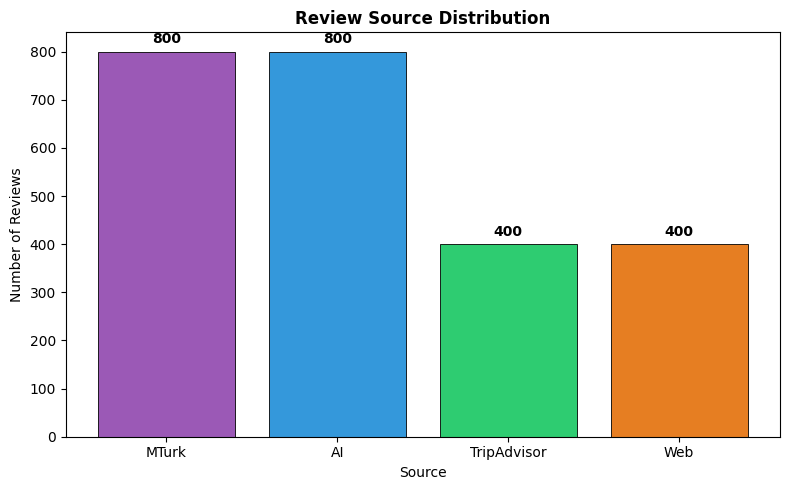

In [9]:
# reviews per source
source_counts = df['source'].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(source_counts.index, source_counts.values,
              color=['#9b59b6', '#3498db', '#2ecc71', '#e67e22'],
              edgecolor='black', linewidth=0.6)

ax.set_title('Review Source Distribution', fontweight='bold')
ax.set_ylabel('Number of Reviews')
ax.set_xlabel('Source')

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{int(height)}',
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### 3.7 Length Summary Statistics

- This table gives the mean, median and standard deviation of characters and words for each class.
- Mean words are Genuine 150.9, Human Fake 146.6 and AI Generated 131.0.
- Median words are 130, 125 and 135.5, and standard deviations are about 90, 85 and 36 (Genuine, Human Fake, AI Generated).
- Genuine and Human Fake are similar in length. AI Generated reviews are much less variable, but not a clear giveaway on their own.

In [10]:
# mean, median and std of length per class
length_summary = (df.groupby('label')[['char_length', 'word_count']]
                    .agg(['mean', 'median', 'std']).round(1)
                    .reindex(CLASS_ORDER))
length_summary.index = CLASS_LABELS
print('Review Length Summary Statistics of Hotel Datasets')
display(length_summary)

Review Length Summary Statistics of Hotel Datasets


char_length               word_count             
                    mean median    std       mean median   std
AI Generated       691.3  715.0  185.3      131.0  135.5  36.0
Human Fake         791.8  680.5  449.0      146.6  125.0  84.8
Genuine            821.0  710.5  484.7      150.9  130.0  89.8

## 4. Load & Explore Amazon Genuine Sample

Here we load a sample of genuine Amazon product reviews and use them for:
- Domain comparison with Hotel Genuine reviews
- A generalisation check of the trained model

- This code loads the Amazon genuine sample, which has **2,000 reviews and 9 columns** (reviewer and review IDs, verified purchase, date, text, star rating, helpful votes, title and product ID).
- It is used only for comparison and the generalisation check, not for training.

In [11]:
# read the amazon data
amazon = pd.read_csv('amazon_genuine_sample.csv')
print(f'Amazon sample shape: {amazon.shape}')
print(f'Columns: {amazon.columns.tolist()}')
amazon.head(3)

Amazon sample shape: (2000, 9)
Columns: ['reviewerId', 'reviewId', 'verifiedPurchase', 'reviewDate', 'reviewText', 'starRating', 'helpfulVote', 'reviewTitle', 'prodId']


,reviewerId,reviewId,verifiedPurchase,reviewDate,reviewText,starRating,helpfulVote,reviewTitle,prodId
0,AHIQOEUXTHAPEDJMGNZODZIG6VCA,R3KVI1Q277SYQK,True,"January 30, 2017",Very nice product. Works great.,4.0,0,Four Stars,B01I8ETGLS
1,AF42IU6JXT3FBGPO5ERZAW5ZRZ7A,R2LPFLRNO8C2MC,False,"June 2, 2015",its ok but my teeth were very sensitive after it,3.0,0,Three Stars,B006QOE5N2
2,AFNSC7DG4GCGHYVWMTWBS4UG7ZFA,R1JARAESLTJ9SR,True,"April 29, 2017","I'm glad I purchased this corkscrew, I was tir...",5.0,0,High quality. Well worth it.,B00WOP3WPY


- This cell removes missing and very short reviews (20 characters or fewer), creating length features and a domain label. **1,795 reviews** remain.
- The star-rating counts show a stray text value ("The", 7 rows), which the next cell removes.
- Ratings are heavily positive (1,215 five-star reviews).

In [12]:
# Basic cleaning of Amazon data
amazon = amazon.dropna(subset=['reviewText']).copy()
amazon['reviewText'] = amazon['reviewText'].astype(str)

# Keep only reasonable length reviews
amazon = amazon[amazon['reviewText'].str.len() > 20].copy()

amazon['char_length'] = amazon['reviewText'].str.len()
amazon['word_count']  = amazon['reviewText'].str.split().str.len()
amazon['domain'] = 'Amazon Genuine'

print(f'Cleaned Amazon genuine reviews: {len(amazon)}')
print('\nStar rating distribution:')
print(amazon['starRating'].value_counts(dropna=False).head(10))

Cleaned Amazon genuine reviews: 1795

Star rating distribution:
starRating
5.0    1215
4.0     257
1.0     125
3.0     122
2.0      69
The       7
Name: count, dtype: int64


- This cell keeps only rows with a numeric `starRating` and converts it to float. **1,788 clean Amazon reviews** remain.
- The rating distribution is 5 stars (1,215), 4 stars (257), 1 star (125), 3 stars (122) and 2 stars (69).

In [13]:
# Remove invalid starRating values
amazon = amazon[pd.to_numeric(amazon['starRating'], errors='coerce').notna()].copy()
amazon['starRating'] = amazon['starRating'].astype(float)

print(f'Cleaned Amazon genuine reviews: {len(amazon)}')
print('\nStar rating distribution:')
print(amazon['starRating'].value_counts(dropna=False).head(10))

Cleaned Amazon genuine reviews: 1788

Star rating distribution:
starRating
5.0    1215
4.0     257
1.0     125
3.0     122
2.0      69
Name: count, dtype: int64


### 4.1 Domain Comparison: Character Length (Hotel Genuine vs Amazon Genuine)

- This box plot compares character length for Hotel Genuine and Amazon Genuine reviews. Amazon reviews are far shorter and more tightly spread, while hotel reviews are much longer. The two genuine domains therefore differ in style, which matters when the model is applied to Amazon reviews.

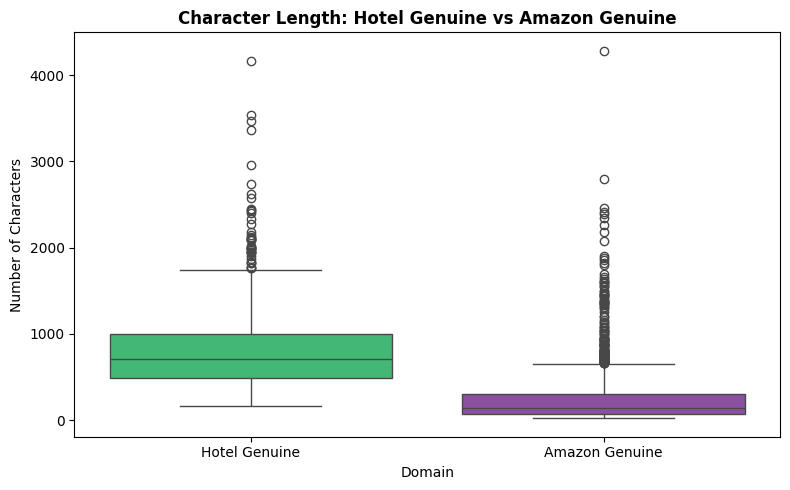

In [14]:
# only genuine hotel reviews, to compare with amazon
hotel_genuine = df[df['label'] == 'truthful'][['char_length', 'word_count']].copy()
hotel_genuine['domain'] = 'Hotel Genuine'

compare_len = pd.concat([
    hotel_genuine[['char_length', 'domain']],
    amazon[['char_length', 'domain']]
], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=compare_len, x='domain', y='char_length',
            palette=DOMAIN_COLORS, ax=ax)

ax.set_title('Character Length: Hotel Genuine vs Amazon Genuine', fontweight='bold')
ax.set_xlabel('Domain')
ax.set_ylabel('Number of Characters')

plt.tight_layout()
plt.show()

### 4.2 Domain Comparison: Word Count

- This box plot repeats the comparison using word counts and shows the same pattern. Hotel reviews contain many more words than Amazon reviews.

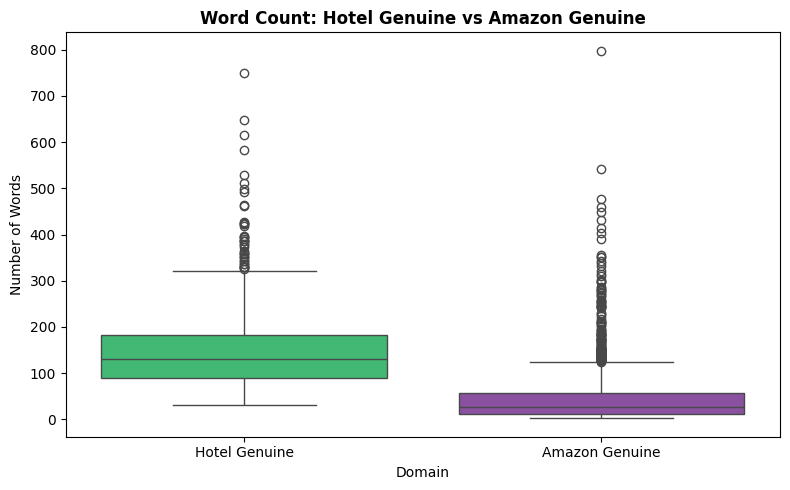

In [15]:
# same comparison using word count
compare_words = pd.concat([
    hotel_genuine[['word_count', 'domain']],
    amazon[['word_count', 'domain']]
], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=compare_words, x='domain', y='word_count',
            palette=DOMAIN_COLORS, ax=ax)

ax.set_title('Word Count: Hotel Genuine vs Amazon Genuine', fontweight='bold')
ax.set_xlabel('Domain')
ax.set_ylabel('Number of Words')

plt.tight_layout()
plt.show()

### 4.3 Average Length Comparison

- The bar chart shows hotel genuine reviews average about **821 characters and 151 words**, while Amazon genuine reviews average about **253 characters and 47 words**. Amazon reviews are roughly three times shorter, a clear domain shift.

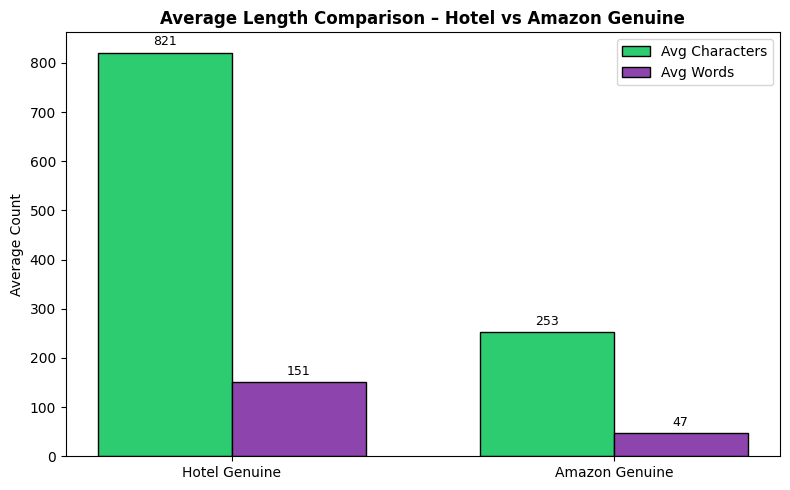

In [16]:
# average length of hotel vs amazon
avg_compare = pd.DataFrame({
    'Domain': ['Hotel Genuine', 'Amazon Genuine'],
    'Avg Characters': [
        hotel_genuine['char_length'].mean(),
        amazon['char_length'].mean()
    ],
    'Avg Words': [
        hotel_genuine['word_count'].mean(),
        amazon['word_count'].mean()
    ]
})

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(avg_compare))
width = 0.35

bars1 = ax.bar(x - width/2, avg_compare['Avg Characters'], width,
               label='Avg Characters', color='#2ecc71', edgecolor='black')
bars2 = ax.bar(x + width/2, avg_compare['Avg Words'], width,
               label='Avg Words', color='#8e44ad', edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(avg_compare['Domain'])
ax.set_title('Average Length Comparison – Hotel vs Amazon Genuine', fontweight='bold')
ax.set_ylabel('Average Count')
ax.legend()

for bar in list(bars1) + list(bars2):
    height = bar.get_height()
    ax.annotate(f'{height:.0f}',
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 5. Text Preprocessing

1. Lowercasing
2. Punctuation & number removal
3. Stop-word removal
4. Lemmatization

- This code defines the text-cleaning function and applies it to both datasets.
- It converts text to lowercase, removes anything that is not a letter, splits the text into words, removes stop-words and very short words (2 characters or fewer) and reduces each word to its base form (lemmatisation).
- The result is stored in a new `clean_text` column.

In [17]:
# stopwords and lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# clean the text: lowercase, remove symbols and stopwords, lemmatize
def preprocess_text(text):
    """Clean and normalise review text."""
    if pd.isna(text):
        return ''
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = word_tokenize(text)
    tokens = [
        lemmatizer.lemmatize(tok)
        for tok in tokens
        if tok not in stop_words and len(tok) > 2
    ]
    return ' '.join(tokens)

df['clean_text'] = df['text'].apply(preprocess_text)
print('Preprocessed main dataset')

amazon['clean_text'] = amazon['reviewText'].apply(preprocess_text)
print('Preprocessed Amazon sample')

Preprocessed main dataset
Preprocessed Amazon sample


## 6. Feature Extraction  
#### TF-IDF & Train/Test Split

- This code encodes the labels as numbers and splits the data **80/20** into **1,920 training** and **480 test** reviews.
- The split is stratified, so each class has 640 training and 160 test reviews.
- Label mapping used: 0 = AI Generated, 1 = Human Fake, 2 = Genuine.

In [18]:
# turn labels into numbers
le = LabelEncoder()
le.fit(CLASS_ORDER)
df['label_id'] = le.transform(df['label'])

print('Label mapping:')
for i, name in enumerate(le.classes_):
    print(f'  {i}: {name} ({CLASS_LABELS[i]})')

X = df['clean_text']
y = df['label_id']

# 80/20 split, same share of each class
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'\nTrain size: {len(X_train)} | Test size: {len(X_test)}')
print('Train class distribution:')
print(pd.Series(y_train).value_counts().sort_index())

Label mapping:
  0: AI generated (AI Generated)
  1: deceptive (Human Fake)
  2: truthful (Genuine)

Train size: 1920 | Test size: 480
Train class distribution:
label_id
0    640
1    640
2    640
Name: count, dtype: int64


- This code converts the cleaned text into TF-IDF features, which score words by how important they are in a review compared with the whole dataset.
- It keeps the 6,000 most useful unigrams and bigrams (words appearing in at least 3 reviews and in no more than 90% of them).
- The vectoriser is fitted on the training set only and then applied to the test set.
- The training matrix has shape **1,920 x 6,000**.

In [19]:
# tf-idf: fit on train only, then apply on test
tfidf = TfidfVectorizer(
    max_features=6000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.90
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f'TF-IDF matrix shape: {X_train_tfidf.shape}')
print(f'Vocabulary size: {len(tfidf.vocabulary_)}')

TF-IDF matrix shape: (1920, 6000)
Vocabulary size: 6000


## 7. Model Training & Evaluation


In [20]:
# train one model and return its scores
def evaluate_model(model, X_tr, y_tr, X_te, y_te, name):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision (macro)': precision_score(y_te, y_pred, average='macro'),
        'Recall (macro)': recall_score(y_te, y_pred, average='macro'),
        'F1-score (macro)': f1_score(y_te, y_pred, average='macro')
    }
    return metrics, y_pred, model

- This code trains four classifiers with default settings on the TF-IDF features and records accuracy and macro precision, recall and F1.
- Logistic Regression scored 0.9333 accuracy, Naive Bayes 0.9250, XGBoost 0.8854 and Random Forest 0.8375.
- The simple linear and probabilistic models outperformed the tree ensembles, which is common with sparse, high-dimensional text data.

In [21]:
# 4 models with default settings
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Naive Bayes': MultinomialNB(),
    'XGBoost': xgb.XGBClassifier(random_state=42)
}

# train each model and store the results
results = []
trained_models = {}
predictions = {}

print('Training models on Hotel dataset:\n')
for name, model in models.items():
    metrics, y_pred, fitted = evaluate_model(
        model, X_train_tfidf, y_train, X_test_tfidf, y_test, name
    )
    results.append(metrics)
    trained_models[name] = fitted
    predictions[name] = y_pred

results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df

Training models on Hotel dataset:



,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9354,0.9353,0.9354,0.9351
Random Forest,0.8604,0.8582,0.8604,0.8587
Naive Bayes,0.9167,0.9161,0.9167,0.9163
XGBoost,0.8729,0.8717,0.8729,0.8722


### 7.1 Model Performance Comparison

- This chart compares accuracy, precision, recall and F1 for the four baseline models.
- Logistic Regression (about 0.93) and Naive Bayes (about 0.92) are clearly highest, followed by XGBoost (about 0.89) and Random Forest (about 0.84).
- Metrics are almost identical within each model because the classes are balanced.
- XGBoost is tuned in the next section to see if its performance can be improved.

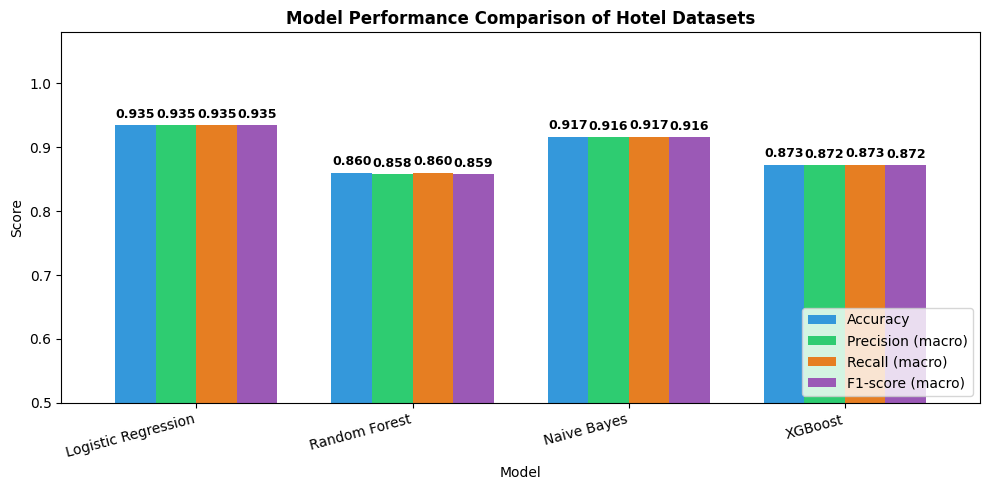

In [22]:
# compare all models in one chart
fig, ax = plt.subplots(figsize=(10, 5))

results_df.plot(
    kind='bar',
    ax=ax,
    width=0.75,
    color=['#3498db', '#2ecc71', '#e67e22', '#9b59b6']
)

ax.set_title('Model Performance Comparison of Hotel Datasets', fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.08)

ax.legend(loc='lower right')

# Add labels above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.3f',
        padding=3,
        fontsize=9,
        fontweight='bold'
    )

ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha='right')

plt.tight_layout()
plt.show()

## 7.2 XGBoost Hyperparameter Tuning

After comparing the baseline models, XGBoost is further optimised using `RandomizedSearchCV` with stratified cross-validation. The search uses **only the training data** and selects the configuration with the highest macro F1-score. The test set is reserved for the final, unbiased evaluation.

- 12 candidate settings are tried with 3-fold cross-validation, scored on macro F1.
- Best cross-validation macro F1 is **0.8548**.
- Best settings: `n_estimators=300`, `max_depth=3`, `learning_rate=0.1`, `min_child_weight=3`, `gamma=0.1`, `subsample=1.0`, `colsample_bytree=1.0`.
- The best model is kept as `xgb_model` and used for all later steps (evaluation, Amazon check, SHAP).

In [23]:
# try different xgboost settings (train data only)
xgb_base = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=len(CLASS_ORDER),
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

xgb_param_distributions = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.2]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_param_distributions,
    n_iter=12,
    scoring='f1_macro',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

xgb_search.fit(X_train_tfidf, y_train)

print('Best cross-validation macro F1:', round(xgb_search.best_score_, 4))
print('\nBest hyperparameters:')
for parameter, value in xgb_search.best_params_.items():
    print(f'{parameter}: {value}')

# keep the best model
xgb_model = xgb_search.best_estimator_

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best cross-validation macro F1: 0.8549

Best hyperparameters:
subsample: 1.0
n_estimators: 300
min_child_weight: 3
max_depth: 3
learning_rate: 0.1
gamma: 0.1
colsample_bytree: 1.0


### 7.3 Test-Set Evaluation of Tuned XGBoost

The best configuration selected through cross-validation is now evaluated once on the held-out test set. This result can be compared directly with the baseline XGBoost result from Section 7.1.

- Tuned XGBoost reaches **0.8750 accuracy** and **0.8747 macro F1** on the test set.
- Baseline XGBoost scored 0.8854 accuracy and 0.8848 macro F1, so tuning did not improve the hotel test score (about 1 point lower).
- Tuning mainly makes the model simpler (`max_depth=3`), which is later shown to help on the Amazon reviews (Section 8).

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Baseline XGBoost,0.8729,0.8717,0.8729,0.8722
Tuned XGBoost,0.8667,0.8662,0.8667,0.8664


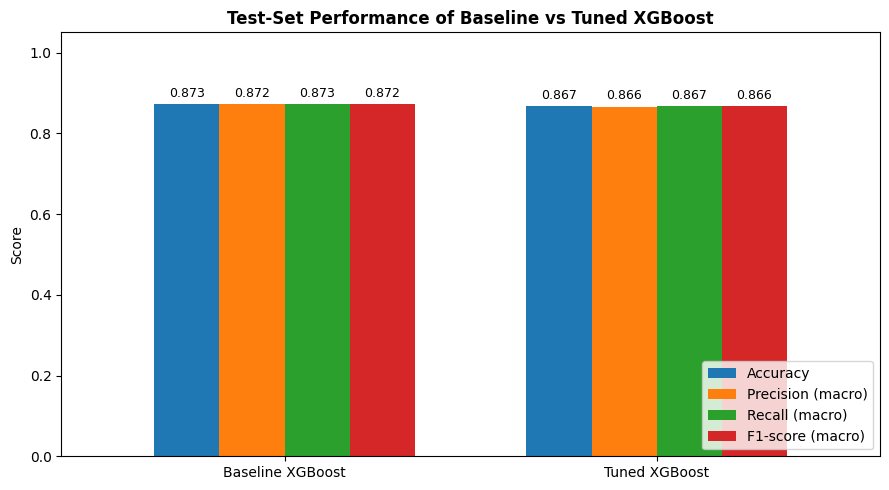

In [24]:
# test score of tuned xgboost vs normal xgboost
y_pred_xgb = xgb_model.predict(X_test_tfidf)

tuned_xgb_metrics = {
    'Model': 'Tuned XGBoost',
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'Precision (macro)': precision_score(y_test, y_pred_xgb, average='macro'),
    'Recall (macro)': recall_score(y_test, y_pred_xgb, average='macro'),
    'F1-score (macro)': f1_score(y_test, y_pred_xgb, average='macro')
}

xgb_comparison = pd.DataFrame([
    results_df.loc['XGBoost'].to_dict(),
    {key: value for key, value in tuned_xgb_metrics.items() if key != 'Model'}
], index=['Baseline XGBoost', 'Tuned XGBoost']).round(4)

display(xgb_comparison)

fig, ax = plt.subplots(figsize=(9, 5))
xgb_comparison.plot(kind='bar', ax=ax, width=0.7)
ax.set_title('Test-Set Performance of Baseline vs Tuned XGBoost', fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

### 7.4 Confusion Matrix of Tuned XGBoost

- The tuned XGBoost confusion matrix shows **420 of 480** test reviews classified correctly.
- AI Generated: 155 correct, 2 confused with Human Fake and 3 with Genuine.
- Human Fake: 132 correct, 27 confused with Genuine and 1 with AI Generated.
- Genuine: 133 correct, 20 confused with Human Fake and 7 with AI Generated.
- Most errors (47 of 60) are between Genuine and Human Fake.

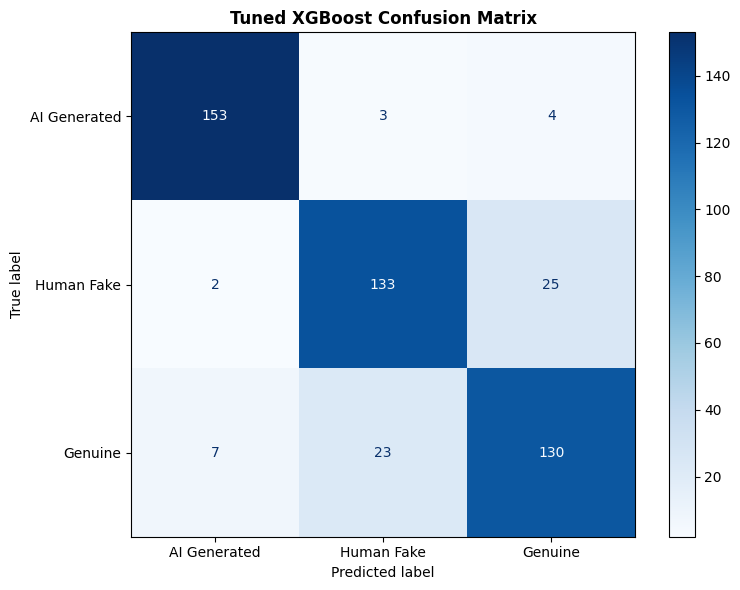

In [25]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred_xgb)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_LABELS)
disp.plot(ax=ax, cmap='Blues', colorbar=True)
ax.set_title('Tuned XGBoost Confusion Matrix', fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Generalisation Check

We take a sample of Amazon genuine reviews, transform them with the same TF-IDF vectorizer, and ask the trained XGBoost model to classify them.  
Ideally most should be predicted as **Genuine**.

### 8.1. Generalisation Check on Tuned XGBoost

- This code samples 400 Amazon genuine reviews, transforms them with the same TF-IDF vectoriser and predicts their class with the tuned XGBoost.
- **368 (92.0%)** are predicted Genuine, **32** Human Fake and **0** AI Generated.
- Over 9 in 10 genuine reviews are recognised correctly despite the change of domain (short product reviews instead of hotel reviews).

In [26]:
# Sample Amazon reviews for the check
amazon_sample = amazon.sample(n=min(400, len(amazon)), random_state=42)

X_amazon_tfidf = tfidf.transform(amazon_sample['clean_text'])
# predict the class of amazon reviews
amazon_pred = xgb_model.predict(X_amazon_tfidf)
amazon_pred_labels = le.inverse_transform(amazon_pred)

pred_counts = pd.Series(amazon_pred_labels).value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)

print('Predicted class distribution on Amazon Genuine sample using Tuned XGBoost:')
print(pred_counts)
print(f'\nPercentage predicted as Genuine using Tuned XGBoost: {100 * pred_counts["truthful"] / len(amazon_sample):.1f}%')

Predicted class distribution on Amazon Genuine sample using Tuned XGBoost:
AI generated      0
deceptive        26
truthful        374
Name: count, dtype: int64

Percentage predicted as Genuine using Tuned XGBoost: 93.5%


### 8.2. Generalisation Check on Logistic Regression

- The same 400 Amazon reviews are classified by Logistic Regression for comparison.
- **330 (82.5%)** are predicted Genuine, **57** Human Fake and **13** AI Generated.
- **Argument:** Logistic Regression performed best on the hotel test set (93.33%), but Tuned XGBoost gave better accuracy in generalisation (92.0% against 82.5% on the same Amazon reviews, with no AI Generated predictions against 13).
- The Amazon sample has genuine reviews only, so this measures how often genuine reviews are wrongly flagged, not full detection accuracy.

In [27]:
# Sample Amazon reviews for the check
amazon_sample = amazon.sample(n=min(400, len(amazon)), random_state=42)

X_amazon_tfidf = tfidf.transform(amazon_sample['clean_text'])

lr = LogisticRegression(random_state=42)
lr_model = lr.fit(X_train_tfidf, y_train)
# predict the class of amazon reviews
amazon_pred = lr_model.predict(X_amazon_tfidf)
amazon_pred_labels = le.inverse_transform(amazon_pred)

pred_counts_lr = pd.Series(amazon_pred_labels).value_counts().reindex(CLASS_ORDER).fillna(0).astype(int)

print('Predicted class distribution on Amazon Genuine sample using Logistic Regression:')
print(pred_counts_lr)
print(f'\nPercentage predicted as Genuine using Logistic Regression: {100 * pred_counts_lr["truthful"] / len(amazon_sample):.1f}%')

Predicted class distribution on Amazon Genuine sample using Logistic Regression:
AI generated     15
deceptive        56
truthful        329
Name: count, dtype: int64

Percentage predicted as Genuine using Logistic Regression: 82.2%


- This chart shows the predicted class distribution for the Amazon sample using Tuned XGBoost.
- Most reviews (368) are predicted Genuine, 32 Human Fake and none AI Generated.
- The sample has no fake reviews, so this shows how often genuine reviews are called Genuine, not full detection accuracy.

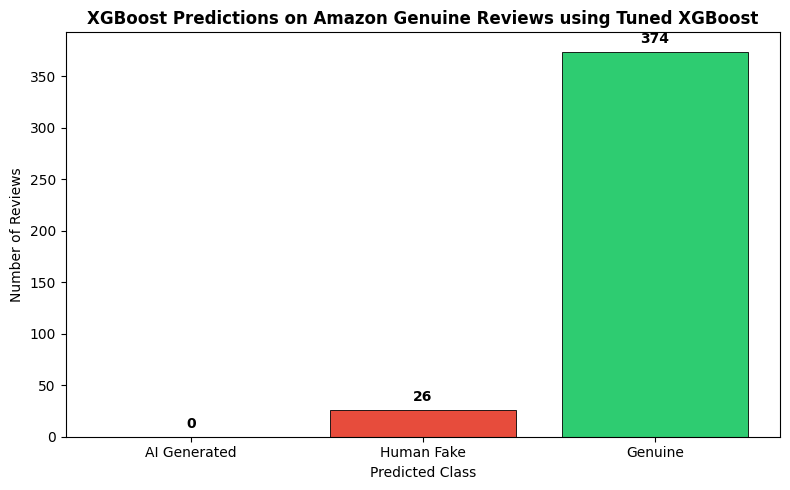

In [28]:
# plot what the model predicted for amazon reviews
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(CLASS_LABELS, pred_counts.values,
              color=[CLASS_COLORS[c] for c in CLASS_ORDER],
              edgecolor='black', linewidth=0.6)

ax.set_title('XGBoost Predictions on Amazon Genuine Reviews using Tuned XGBoost', fontweight='bold')
ax.set_ylabel('Number of Reviews')
ax.set_xlabel('Predicted Class')

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{int(height)}',
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## 9. Explainability with SHAP

- This code creates a SHAP TreeExplainer for the tuned XGBoost model and computes SHAP values for 200 test reviews.
- SHAP values show how much each word pushes a prediction towards or away from each class.

In [29]:
# explain predictions using shap
explainer = shap.TreeExplainer(xgb_model)

print('Computing SHAP values on a sample of the test set:')
sample_size = min(200, X_test_tfidf.shape[0])
X_sample = X_test_tfidf[:sample_size]

shap_values = explainer.shap_values(X_sample)
print("SHAP values ready.")

Computing SHAP values on a sample of the test set:
SHAP values ready.


- This code splits the SHAP values into one set per class (0 = AI Generated, 1 = Human Fake, 2 = Genuine) and converts the sampled TF-IDF matrix to a dense array for plotting.

In [30]:
feature_names = tfidf.get_feature_names_out()

# Extract SHAP values for each class
if isinstance(shap_values, list):
    shap_ai_generated = shap_values[0]
    shap_human_fake = shap_values[1]
    shap_genuine = shap_values[2]
else:
    shap_ai_generated = shap_values[:, :, 0]
    shap_human_fake = shap_values[:, :, 1]
    shap_genuine = shap_values[:, :, 2]

# Convert sparse matrix to dense
X_sample_dense = X_sample.toarray()

### 9.1 Top Features for Genuine Class

- This chart shows the top words for the Genuine class.
- The leading words are *chicago, location, luxury, great, michigan, arrived, nice, smelled, helpful, call, construction*.
- Many are place names and concrete stay details (*michigan, talbott hotel, house hilton, construction, hour, smelled*), which fits genuine guests describing real experiences.
- Some words (*chicago, michigan*) come from the hotel corpus itself, so they may not carry over to other domains.

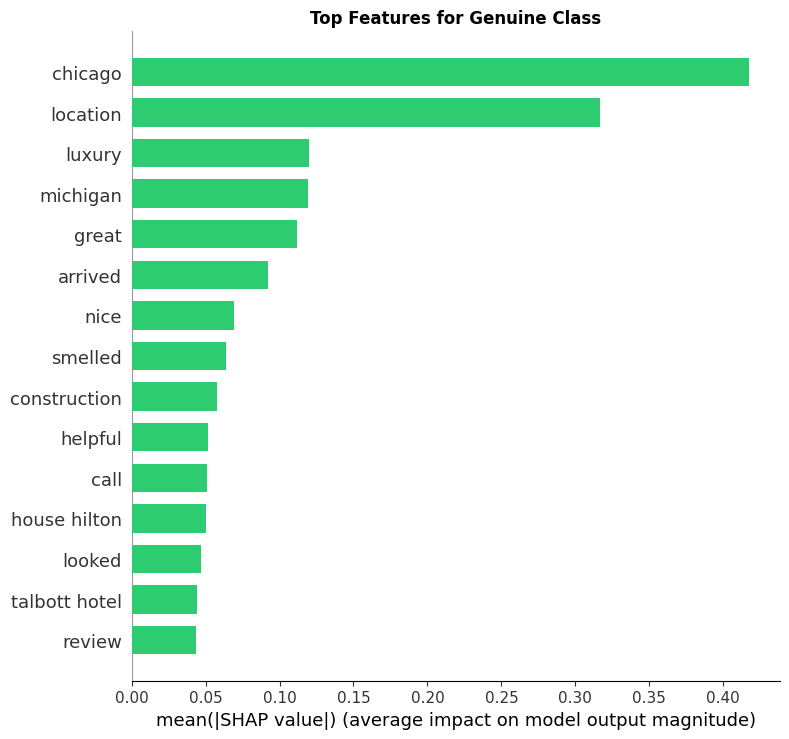

In [31]:
# top 15 words for genuine class
shap.summary_plot(
    shap_genuine, X_sample_dense,
    feature_names=feature_names,
    plot_type='bar',
    max_display=15,
    show=False,
    color='#2ecc71'
)

plt.title('Top Features for Genuine Class', fontweight='bold')
plt.tight_layout()
plt.show()

### 9.2 Top Features for Human Fake Class

- This chart shows the top words for the Human Fake class.
- The strongest are *small, chicago, floor, morning, quiet, breakfast, food, elevator, definitely, luxury*.
- Fake writers focus on room and hotel features (*floor, elevator, lobby, bathroom, street*) and add emphatic words (*definitely, luxury, experience*).

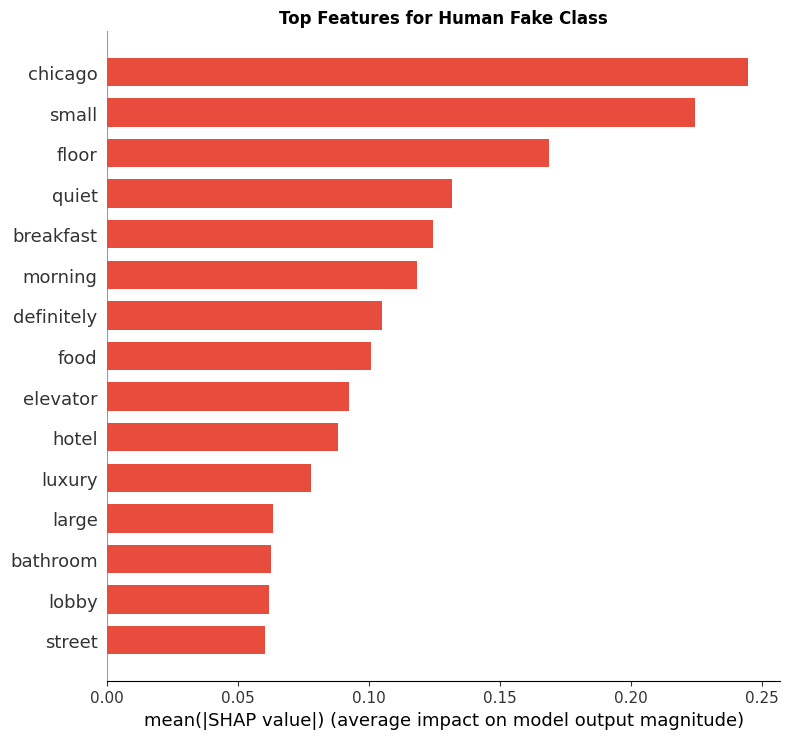

In [32]:
# top 15 words for human fake class
shap.summary_plot(
    shap_human_fake, X_sample_dense,
    feature_names=feature_names,
    plot_type='bar',
    max_display=15,
    show=False,
    color='#e74c3c'
)

plt.title('Top Features for Human Fake Class', fontweight='bold')
plt.tight_layout()
plt.show()

### 9.3 Top Features for AI Generated Class

- This chart ranks the top 15 words by mean absolute SHAP value for the AI Generated class.
- Leading words are *chicago, hotel, room, bed, staff, desk, said, morning, evening, get, asked, front desk*.
- These are generic hotel-service words and everyday narration (*said, asked, front desk*), which fits AI-written stays built from a typical pattern.

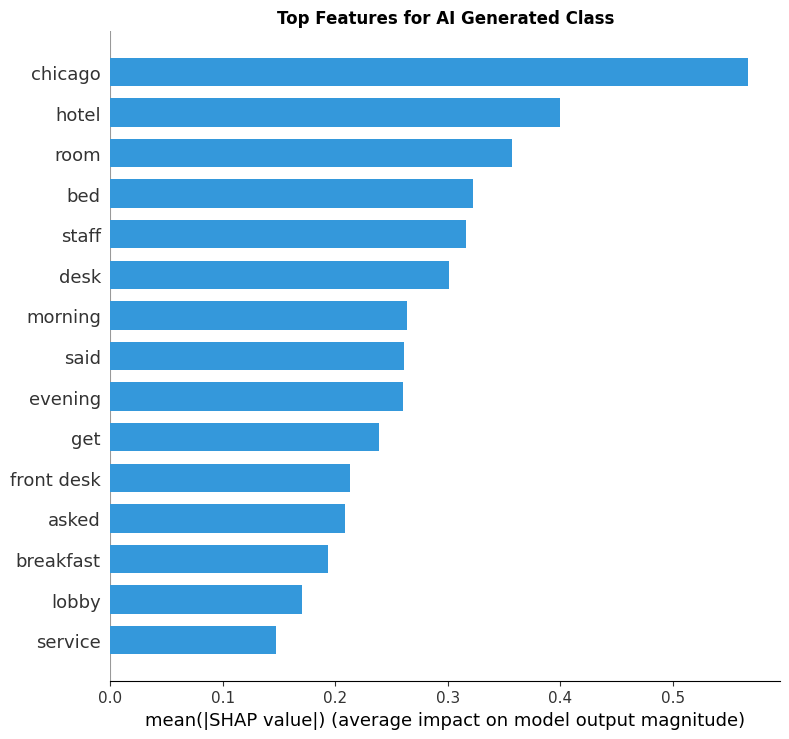

In [33]:
# top 15 words for AI generated class
shap.summary_plot(
    shap_ai_generated, X_sample_dense,
    feature_names=feature_names,
    plot_type='bar',
    max_display=15,
    show=False,
    color='#3498db'
)

plt.title('Top Features for AI Generated Class', fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Final Conclusion

### 10.1 What Was Done:
- Built a 3-class review classifier (Genuine, Human Fake, AI Generated) on 2,400 hotel reviews (800 per class) using TF-IDF features from the review text only.
- Compared four models with default settings: Logistic Regression, Naive Bayes, Random Forest and XGBoost.
- Tuned XGBoost with `RandomizedSearchCV` (3-fold CV, macro F1) and tested it once on the held-out test set.
- Checked the tuned XGBoost and Logistic Regression on the same 400 genuine Amazon reviews (different domain).
- Used SHAP to see which words push the model towards each class.

### 10.2 Answers to the Research Questions:
- **RQ1: Can XGBoost accurately classify the three review types?**
  - Yes, with good accuracy. The tuned XGBoost reached **87.50% accuracy** and **0.8747 macro F1** (420 of 480 test reviews correct). The default XGBoost scored 88.54%, so tuning did not raise the hotel test score.
  - AI Generated reviews were separated best (F1 0.960, 155 of 160 correct).
  - Human Fake (F1 0.841) and Genuine (F1 0.824) were harder, and 47 of the 60 errors are between these two.
  - XGBoost was not the highest scoring model on the hotel data: Logistic Regression (93.33%) and Naive Bayes (92.50%) scored higher even with default settings.
- **RQ2: Which textual features contribute most?**
  - Genuine: place names and specific stay details (*chicago, location, michigan, arrived, smelled, construction*).
  - Human Fake: room and hotel feature words with emphatic words (*small, floor, quiet, breakfast, elevator, definitely, luxury*).
  - AI Generated: generic hotel-service and narration words (*hotel, room, bed, staff, desk, said, asked, front desk*).
- **RQ3: Can SHAP effectively explain the predictions?**
  - Yes. The per-class SHAP bar plots give readable word lists that match how each type of review is written.
  - The plots show average strength of words, not direction, and some top words are specific to this hotel corpus.
- **RQ4: Do SHAP explanations increase participant confidence?**
  - Not tested in this notebook.

### 10.3 Key Findings:
- The classes are balanced, and Human Fake and Genuine reviews have similar lengths, so the model relies mainly on wording, not review length or source.
- **Logistic Regression performed best on the hotel test set (93.33%), but Tuned XGBoost gave better accuracy in generalisation:** on the same 400 Amazon genuine reviews it predicted 92.0% as Genuine, against 82.5% for Logistic Regression, and made no AI Generated predictions (Logistic Regression made 13).
- AI-written reviews were the easiest to detect. Telling real reviews from human-written fakes is the main challenge.
- Tuned XGBoost transfers well to another domain despite much shorter reviews (about 47 words against 151 for hotels).

### 10.4 Limitations:
- AI reviews come from one tool and one prompt, so results may not hold for other AI tools.
- The Amazon sample has only genuine reviews and is a single sample of 400, so it cannot measure full detection performance there.
- Only XGBoost was tuned, and results come from a single 80/20 split.
- Some important SHAP words (such as *chicago* and *michigan*) come from the hotel corpus and may not transfer.

### 10.5 Recommendations and Future Work:
- Report Logistic Regression as the strongest model on hotel data, and Tuned XGBoost as the model that generalised better and supports SHAP.
- Add AI reviews from several different tools and Amazon fake reviews to test generalisation.